# Extended Kalman Filter Localisation

Fuse uncertain wheel motion with intermittent range and bearing observations of known landmarks.

The prediction linearises a unicycle model. The update linearises the sensor model at the current pose and wraps bearing errors at ±π. A Joseph-form covariance update preserves numerical symmetry and positive semidefiniteness to rounding precision.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from estimation import motion, ekf_step, landmark_observation, wrap

## Compare odometry with landmark updates

The estimator and odometry-only baseline receive exactly the same noisy velocity measurements. Truth is retained solely for scoring.

Position RMSE (m), odometry / EKF [0.2257 0.0343] | EKF heading RMSE (rad) 0.0131


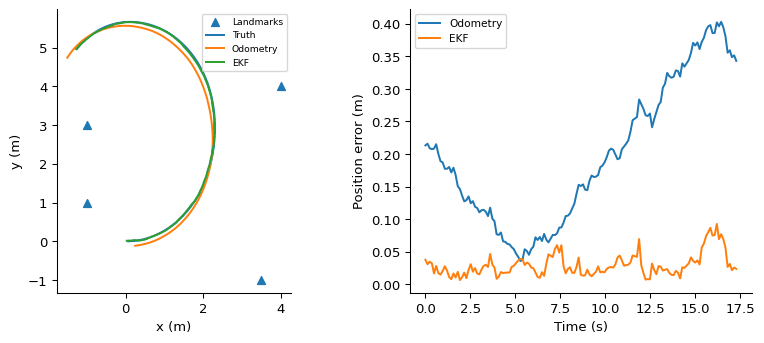

In [2]:
rng = np.random.default_rng(71)
dt = 0.12
landmarks = np.array([[-1.0, 1.0], [3.5, -1.0], [4.0, 4.0], [-1.0, 3.0]])
Q = np.diag([0.09**2, 0.05**2])
V = np.diag([0.09**2, 0.035**2])
truth = np.zeros(3)
est = np.array([0.18, -0.12, 0.09])
odom = est.copy()
P = np.diag([0.3**2, 0.3**2, 0.16**2])
states = []
min_eig = float("inf")
for k in range(145):
    control = np.array([0.55 + 0.08 * np.sin(k * 0.08), 0.22 + 0.10 * np.cos(k * 0.055)])
    truth = motion(truth, control, dt)
    measured = control + rng.multivariate_normal([0, 0], Q)
    odom = motion(odom, measured, dt)
    visible = landmarks if k % 4 == 0 else landmarks[:0]
    obs = [landmark_observation(truth, l) + rng.multivariate_normal([0, 0], V) for l in visible]
    est, P = ekf_step(est, P, measured, obs, visible, dt, Q, V)
    min_eig = min(min_eig, np.linalg.eigvalsh(P).min())
    states.append([truth.copy(), odom.copy(), est.copy()])
data = np.asarray(states)
e = np.linalg.norm(data[:, :, 0:2] - data[:, 0:1, 0:2], axis=2)
rmse = np.sqrt(np.mean(e[:, 1:] ** 2, axis=0))
heading = np.sqrt(np.mean(wrap(data[:, 2, 2] - data[:, 0, 2]) ** 2))
print(
    "Position RMSE (m), odometry / EKF",
    rmse.round(4),
    "| EKF heading RMSE (rad)",
    round(heading, 4),
)
assert min_eig > 0 and rmse[1] < rmse[0]
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3.5), constrained_layout=True)
a.scatter(*landmarks.T, marker="^", label="Landmarks")
for j, label in enumerate(["Truth", "Odometry", "EKF"]):
    a.plot(*data[:, j, :2].T, label=label)
a.set(aspect="equal", xlabel="x (m)", ylabel="y (m)")
a.legend(fontsize=7)
b.plot(dt * np.arange(len(e)), e[:, 1:], label=["Odometry", "EKF"])
b.set(xlabel="Time (s)", ylabel="Position error (m)")
b.legend(fontsize=8)
plt.show()

## Interpreting the result

The measured benefit depends on noise, landmark geometry and observation rate. Landmark correspondences and map coordinates are supplied in this problem.

## Exercise

Reduce measurement frequency and examine how position and heading drift change.

## References

[Dellaert and Hutchinson, Introduction to Robotics and Perception](https://www.roboticsbook.org/)

[Welch and Bishop, an introduction to the Kalman filter](https://www.cs.unc.edu/~welch/kalman/)